In [37]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

plt.rcParams["axes.unicode_minus"] = False

DATA_PATH = "2026_ionosphere_data.csv"

LATENT_DIMS = [2, 5, 10]
SNAPSHOTS_AT = [10, 100, 500, 1000]
SNAPSHOTS_SUP = [10, 50, 100, 200]
MAIN_SEED = 42
N_SEEDS = 10
CV_FOLDS = 3
BATCH = 32
ENSEMBLE_K = 5

BASE = dict(hidden=[32, 16], drop=0.0, l2=0.0, lr=0.05, mom=0.0,
            act="relu", cosine=False, epochs=300)
VIS_CFG = {**BASE, "epochs": 1000}

COMMON = dict(lr=0.02, mom=0.9, act="tanh", cosine=True, epochs=200, patience=30)
GRID = [{**COMMON, **g} for g in [
    dict(hidden=[32, 16], drop=0.0, l2=1e-2),
    dict(hidden=[32, 16], drop=0.2, l2=1e-2),
    dict(hidden=[64, 32], drop=0.3, l2=1e-2),
    dict(hidden=[64, 32], drop=0.3, l2=3e-2),
]]


def cfg_str(c):
    return f"hidden={c['hidden']}, dropout={c['drop']}, L2={c['l2']}"

In [38]:
df = pd.read_csv(DATA_PATH, header=None)
X_all = df.iloc[:, :-1].to_numpy(dtype=np.float64)
y_all = (df.iloc[:, -1].to_numpy() == "g").astype(int)
print("資料大小:", df.shape, "| g:", (y_all == 1).sum(), "| b:", (y_all == 0).sum())


def stratified_split(y, frac, rng):
    rest, picked = [], []
    for c in np.unique(y):
        idx = rng.permutation(np.where(y == c)[0])
        k = int(round(len(idx) * frac))
        picked.append(idx[:k])
        rest.append(idx[k:])
    return rng.permutation(np.concatenate(rest)), rng.permutation(np.concatenate(picked))


def make_data(seed):
    rng = np.random.RandomState(seed)
    rest, te = stratified_split(y_all, 0.2, rng)
    tr_pos, va_pos = stratified_split(y_all[rest], 0.15, rng)
    tr, va = rest[tr_pos], rest[va_pos]
    mu, sd = X_all[tr].mean(0), X_all[tr].std(0)
    sd[sd == 0] = 1.0
    f = lambda i: (X_all[i] - mu) / sd
    return dict(Xtr=f(tr), ytr=y_all[tr], Xva=f(va), yva=y_all[va],
                Xte=f(te), yte=y_all[te])

資料大小: (351, 35) | g: 225 | b: 126


In [39]:
class MLP:
    def __init__(self, sizes, cfg):
        self.cfg = cfg
        self.L = len(sizes) - 1
        self.lr, self.l2, self.mom = cfg["lr"], cfg["l2"], cfg["mom"]
        self.p, self.act = cfg["drop"], cfg["act"]
        self.W, self.b = [], []
        for i in range(self.L):
            is_tanh_latent = (i == self.L - 2 and self.act == "tanh")
            scale = np.sqrt((1.0 if is_tanh_latent else 2.0) / sizes[i])   # He / Xavier 初始化
            self.W.append(np.random.randn(sizes[i], sizes[i + 1]) * scale)
            self.b.append(np.zeros((1, sizes[i + 1])))
        self.vW = [np.zeros_like(w) for w in self.W]
        self.vb = [np.zeros_like(b) for b in self.b]

    @staticmethod
    def softmax(z):
        z = z - z.max(1, keepdims=True)
        e = np.exp(z)
        return e / e.sum(1, keepdims=True)

    def forward(self, X, train=False):
        a = X
        self.z, self.a, self.mask = [], [X], []
        for i in range(self.L):
            z = a @ self.W[i] + self.b[i]
            m = None
            if i == self.L - 1:
                a = self.softmax(z)
            elif i == self.L - 2:                # latent 層：不做 dropout
                a = np.tanh(z) if self.act == "tanh" else np.maximum(0, z)
            else:
                a = np.maximum(0, z)
                if train and self.p > 0:         # inverted dropout
                    m = (np.random.rand(*a.shape) > self.p) / (1.0 - self.p)
                    a = a * m
            self.z.append(z)
            self.a.append(a)
            self.mask.append(m)
        return a

    def backward(self, Y):
        m = Y.shape[0]
        dZ = (self.a[-1] - Y) / m                # softmax + cross-entropy
        gW, gb = [None] * self.L, [None] * self.L
        for i in reversed(range(self.L)):
            gW[i] = self.a[i].T @ dZ + self.l2 * self.W[i]
            gb[i] = dZ.sum(0, keepdims=True)
            if i > 0:
                dA = dZ @ self.W[i].T
                k = i - 1
                if self.mask[k] is not None:
                    dA = dA * self.mask[k]
                if k == self.L - 2 and self.act == "tanh":
                    dZ = dA * (1.0 - self.a[k + 1] ** 2)
                else:
                    dZ = dA * (self.z[k] > 0)
        for i in range(self.L):                  # SGD + momentum
            self.vW[i] = self.mom * self.vW[i] - self.lr * gW[i]
            self.vb[i] = self.mom * self.vb[i] - self.lr * gb[i]
            self.W[i] += self.vW[i]
            self.b[i] += self.vb[i]

    def latent(self, X):
        self.forward(X)
        return self.a[-2]


def ce(p, y, eps=1e-9):
    return -np.mean(np.log(p[np.arange(len(y)), y] + eps))


def err(p, y):
    return np.mean(p.argmax(1) != y)


def train(d, dim, seed, cfg, snapshots=(), track=True):
    """mini-batch SGD 訓練。回傳 model, 歷史紀錄, latent 快照, 最終結果
    若 cfg 內 patience>0 且資料含驗證集，則以驗證 loss 做 early stopping 並還原最佳權重。"""
    np.random.seed(seed)
    model = MLP([34] + cfg["hidden"] + [dim, 2], cfg)
    Xtr, ytr, Xte, yte = d["Xtr"], d["ytr"], d["Xte"], d["yte"]
    Ytr = np.eye(2)[ytr]
    n, E = len(ytr), cfg["epochs"]
    H = dict(loss=[], te_loss=[], va_loss=[], tr=[], te=[])
    snaps = {}
    patience = cfg.get("patience", 0)
    use_es = patience > 0 and "Xva" in d
    best_loss, best_ep, wait, best_state = np.inf, E, 0, None

    for ep in range(1, E + 1):
        if cfg["cosine"]:
            model.lr = cfg["lr"] * (0.01 + 0.99 * 0.5 * (1 + np.cos(np.pi * (ep - 1) / E)))
        perm = np.random.permutation(n)
        for s in range(0, n, BATCH):
            idx = perm[s:s + BATCH]
            model.forward(Xtr[idx], train=True)
            model.backward(Ytr[idx])
        if track:
            ptr, pte = model.forward(Xtr), model.forward(Xte)
            H["loss"].append(ce(ptr, ytr)); H["te_loss"].append(ce(pte, yte))
            H["tr"].append(err(ptr, ytr));  H["te"].append(err(pte, yte))
        if use_es:
            lva = ce(model.forward(d["Xva"]), d["yva"])
            H["va_loss"].append(lva)
            if lva < best_loss - 1e-4:
                best_loss, best_ep, wait = lva, ep, 0
                best_state = ([w.copy() for w in model.W], [b.copy() for b in model.b])
            else:
                wait += 1
                if wait >= patience:
                    break
        if ep in snapshots:
            snaps[ep] = (model.latent(Xtr), model.latent(Xte),
                         model.W[-1].copy(), model.b[-1].copy(),
                         err(model.forward(Xtr), ytr), err(model.forward(Xte), yte))

    if use_es and best_state is not None:
        model.W, model.b = best_state            # 還原驗證 loss 最低的權重
    res = dict(train_err=err(model.forward(Xtr), ytr),
               test_err=err(model.forward(Xte), yte),
               stop_ep=best_ep if use_es else E)
    return model, H, snaps, res


def train_vis(d, dim, seed, cfg, snapshots, max_tries=5):
    """(c) 專用：ReLU latent 偶爾會 dead ReLU（訓練誤差很高）。
    若發生，換 seed 重訓並印出訊息（報告中需如實說明）。"""
    for t in range(max_tries):
        out = train(d, dim, seed + t, cfg, snapshots=snapshots, track=False)
        if out[3]["train_err"] < 0.2:
            break
        print(f"  [dim={dim}] seed={seed + t} 訓練誤差 {out[3]['train_err']:.3f} 偏高(dead ReLU)，換 seed 重訓")
    return out


def cv_select(d, seed):
    """只用訓練資料做 stratified k-fold CV 挑超參數（不碰驗證集與測試集）"""
    X, y = d["Xtr"], d["ytr"]
    rng = np.random.RandomState(seed + 1000)
    folds = [[] for _ in range(CV_FOLDS)]
    for c in np.unique(y):
        idx = rng.permutation(np.where(y == c)[0])
        for k, part in enumerate(np.array_split(idx, CV_FOLDS)):
            folds[k].extend(part.tolist())
    folds = [np.array(f) for f in folds]

    scores = []
    for cfg in GRID:
        errs, ces = [], []
        for k in range(CV_FOLDS):
            va = folds[k]
            tr = np.concatenate([folds[j] for j in range(CV_FOLDS) if j != k])
            dk = dict(Xtr=X[tr], ytr=y[tr], Xte=X[va], yte=y[va])   # 無 Xva -> 不 early stop
            m, _, _, r = train(dk, 5, seed * 10 + k, cfg, track=False)
            errs.append(r["test_err"])
            ces.append(ce(m.forward(X[va]), y[va]))
        scores.append((np.mean(errs), np.mean(ces)))
    best = min(range(len(GRID)), key=lambda i: (round(scores[i][0], 4), scores[i][1]))
    return best, scores


def ensemble_test_err(d, dim, seed, cfg, K=ENSEMBLE_K):
    P = 0
    for k in range(K):
        m, *_ = train(d, dim, seed * 100 + k, cfg, track=False)
        P = P + m.forward(d["Xte"])
    return err(P / K, d["yte"])

In [40]:
d = make_data(MAIN_SEED)
print(f"Train={len(d['ytr'])}, Val={len(d['yva'])}, Test={len(d['yte'])}")

best_i, cv_scores = cv_select(d, MAIN_SEED)
cfg = GRID[best_i]
print("\n[CV 超參數選擇]（只用訓練資料）")
for i, (e_, l_) in enumerate(cv_scores):
    mark = "  <- 選中" if i == best_i else ""
    print(f"  {cfg_str(GRID[i])}: CV err={e_:.4f}, CV loss={l_:.4f}{mark}")

model, H, _, res = train(d, 2, MAIN_SEED, cfg)
print("\n訓練完成。")

Train=239, Val=42, Test=70

[CV 超參數選擇]（只用訓練資料）
  hidden=[32, 16], dropout=0.0, L2=0.01: CV err=0.0752, CV loss=0.2317
  hidden=[32, 16], dropout=0.2, L2=0.01: CV err=0.0544, CV loss=0.1574  <- 選中
  hidden=[64, 32], dropout=0.3, L2=0.01: CV err=0.0585, CV loss=0.1875
  hidden=[64, 32], dropout=0.3, L2=0.03: CV err=0.0669, CV loss=0.2245

訓練完成。


In [41]:
print("===== (1) Network architecture =====")
print(f"34 - {' - '.join(map(str, cfg['hidden']))} - 2(latent) - 2(output)")
print(f"  hidden layers: {len(cfg['hidden'])} 層，神經元數 {cfg['hidden']}，ReLU")
print(f"  latent layer : 2 個神經元，{cfg['act']}")
print(f"  output layer : 2 個神經元，Softmax")
print(f"  lr={cfg['lr']} (cosine decay), momentum={cfg['mom']}, dropout={cfg['drop']}, "
      f"L2={cfg['l2']}, batch={BATCH}")
print(f"  max epochs={cfg['epochs']}, early stopping patience={cfg['patience']}, "
      f"實際採用 epoch={res['stop_ep']}")

print("\n===== (3)(4) Error rate =====")
print(f"Train samples={len(d['ytr'])}, Test samples={len(d['yte'])}")
print(f"Training error rate = {res['train_err']:.4f}")
print(f"Test error rate     = {res['test_err']:.4f}")
print(f"(測試集每錯 1 筆約 {100/len(d['yte']):.2f}%)")

===== (1) Network architecture =====
34 - 32 - 16 - 2(latent) - 2(output)
  hidden layers: 2 層，神經元數 [32, 16]，ReLU
  latent layer : 2 個神經元，tanh
  output layer : 2 個神經元，Softmax
  lr=0.02 (cosine decay), momentum=0.9, dropout=0.2, L2=0.01, batch=32
  max epochs=200, early stopping patience=30, 實際採用 epoch=39

===== (3)(4) Error rate =====
Train samples=239, Test samples=70
Training error rate = 0.0042
Test error rate     = 0.1143
(測試集每錯 1 筆約 1.43%)


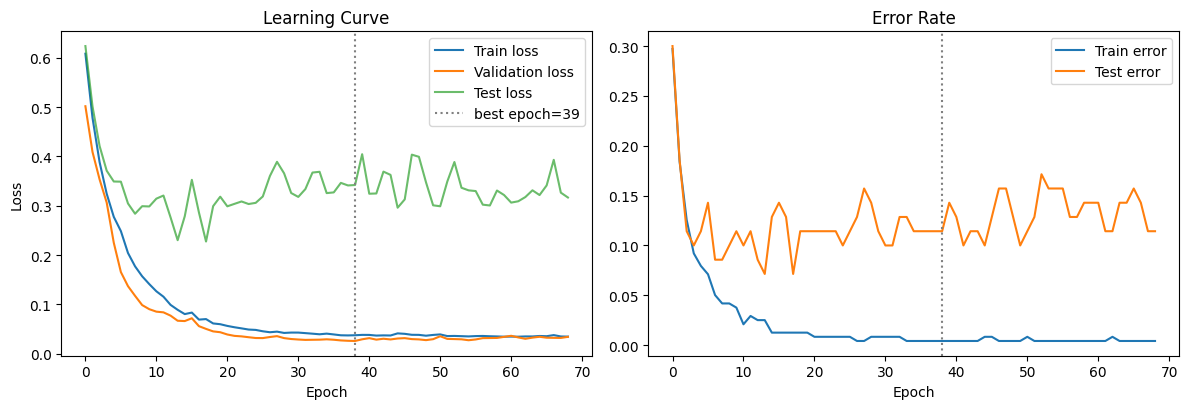

In [42]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(H["loss"], label="Train loss")
ax[0].plot(H["va_loss"], label="Validation loss")
ax[0].plot(H["te_loss"], label="Test loss", alpha=0.7)
ax[0].axvline(res["stop_ep"] - 1, color="gray", ls=":", label=f"best epoch={res['stop_ep']}")
ax[0].set_title("Learning Curve")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].legend()

ax[1].plot(H["tr"], label="Train error")
ax[1].plot(H["te"], label="Test error")
ax[1].axvline(res["stop_ep"] - 1, color="gray", ls=":")
ax[1].set_title("Error Rate"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout()
plt.savefig("learning_curve_classification.png", dpi=150)
plt.show()

In [43]:
def plot_latent_simple(ax, Ztr, ytr, title, Zte=None, yte=None):
    """訓練點(圓) + 測試點(三角)；高維用『訓練集』的 PCA 投影"""
    if Ztr.shape[1] > 2:
        mu = Ztr.mean(0)
        _, _, Vt = np.linalg.svd(Ztr - mu, full_matrices=False)
        Ptr = (Ztr - mu) @ Vt[:2].T
        Pte = None if Zte is None else (Zte - mu) @ Vt[:2].T
        ax.set_xlabel("PC1 of latent features", fontsize=8)
        ax.set_ylabel("PC2 of latent features", fontsize=8)
    else:
        Ptr, Pte = Ztr, Zte
    for cls, col, name in [(0, "blue", "b"), (1, "lime", "g")]:
        ax.scatter(Ptr[ytr == cls, 0], Ptr[ytr == cls, 1], c=col, s=20,
                   edgecolors="k", linewidths=0.8, label=f"train {name}")
        if Pte is not None:
            ax.scatter(Pte[yte == cls, 0], Pte[yte == cls, 1], c=col, s=55,
                       marker="^", edgecolors="r", linewidths=1.0, label=f"test {name}")
    ax.set_title(title, fontsize=9)
    ax.legend(fontsize=6)


def plot_latent(ax, snap, ytr, yte, dim, title, legend=False):
    """含測試點與決策邊界；dim>2 時 x 軸為決策方向 logit(g)-logit(b)"""
    Ztr, Zte, Wl, bl, _, _ = snap
    w = Wl[:, 1] - Wl[:, 0]
    c = bl[0, 1] - bl[0, 0]
    if dim == 2:
        Ptr, Pte = Ztr, Zte
        xl, yl = "latent unit 1", "latent unit 2"
    else:
        wn = w / (np.linalg.norm(w) + 1e-12)
        Rtr = Ztr - np.outer(Ztr @ wn, wn)
        Rte = Zte - np.outer(Zte @ wn, wn)
        mu = Rtr.mean(0, keepdims=True)
        _, _, Vt = np.linalg.svd(Rtr - mu, full_matrices=False)
        Ptr = np.c_[Ztr @ w + c, (Rtr - mu) @ Vt[0]]
        Pte = np.c_[Zte @ w + c, (Rte - mu) @ Vt[0]]
        xl, yl = "logit(g) - logit(b)", "PC1 (orthogonal to decision axis)"

    for cls, col, name in [(0, "navy", "b"), (1, "green", "g")]:
        ax.scatter(Ptr[ytr == cls, 0], Ptr[ytr == cls, 1], c=col, s=12, alpha=0.45,
                   label=f"{name} train")
        ax.scatter(Pte[yte == cls, 0], Pte[yte == cls, 1], c=col, s=40, marker="^",
                   edgecolors="k", linewidths=0.6, label=f"{name} test")
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
    if dim == 2:
        if abs(w[1]) > 1e-9:
            xs = np.array([x0, x1])
            ax.plot(xs, -(w[0] * xs + c) / w[1], "r--", lw=1.3, label="decision boundary")
        elif abs(w[0]) > 1e-9:
            ax.axvline(-c / w[0], color="r", ls="--", lw=1.3, label="decision boundary")
    else:
        ax.axvline(0, color="r", ls="--", lw=1.3, label="decision boundary")
    ax.set_xlim(x0, x1); ax.set_ylim(y0, y1)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel(xl, fontsize=8); ax.set_ylabel(yl, fontsize=8)
    if legend:
        ax.legend(fontsize=7, loc="best")

latent_dim=2: final train_err=0.0000, test_err=0.1143
latent_dim=5: final train_err=0.0000, test_err=0.1143
latent_dim=10: final train_err=0.0000, test_err=0.1429


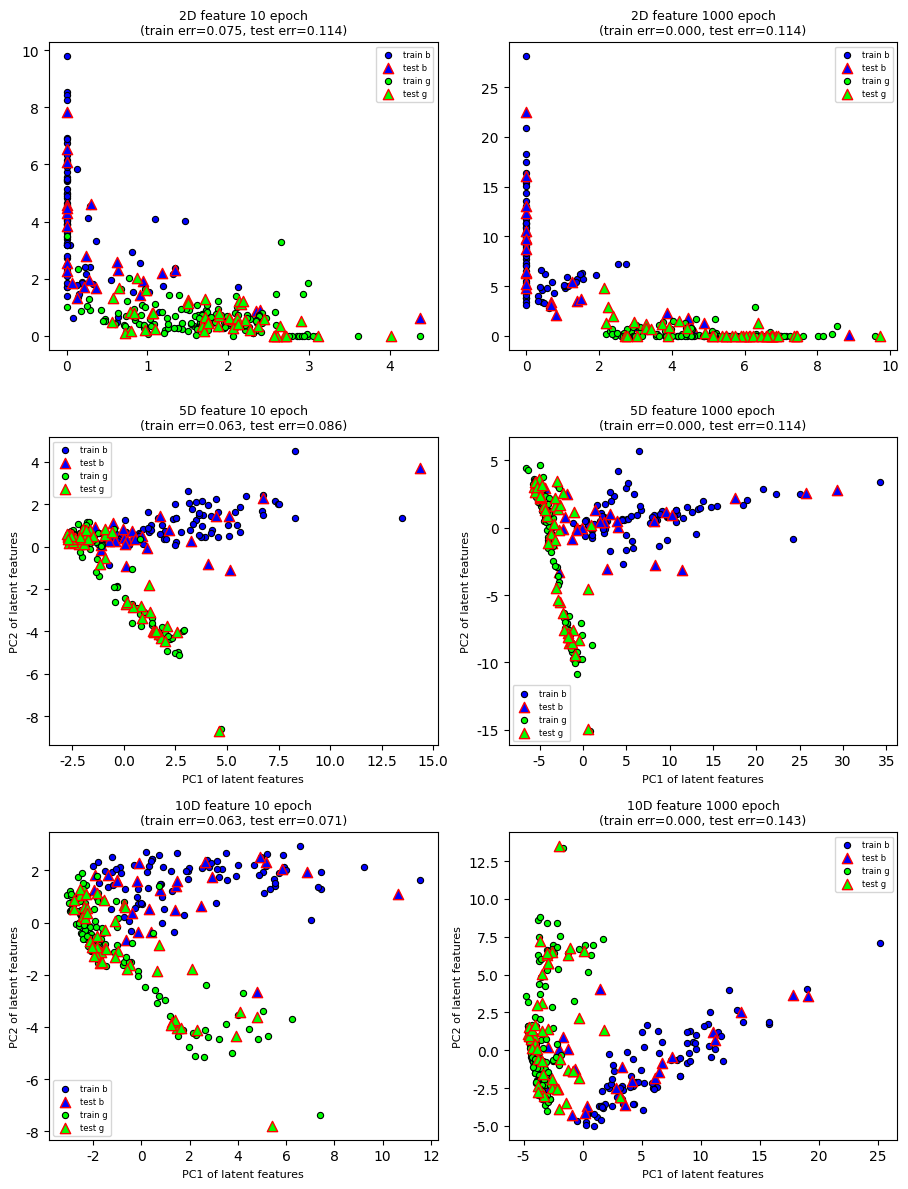

In [46]:
SNAPSHOTS_AT = [10, 1000]
fig, axes = plt.subplots(len(LATENT_DIMS), len(SNAPSHOTS_AT),
                         figsize=(4.6 * len(SNAPSHOTS_AT), 4.0 * len(LATENT_DIMS)))
for r, dim in enumerate(LATENT_DIMS):
    _, _, snaps, rs = train_vis(d, dim, MAIN_SEED, VIS_CFG, SNAPSHOTS_AT)
    print(f"latent_dim={dim}: final train_err={rs['train_err']:.4f}, test_err={rs['test_err']:.4f}")
    for c_, ep in enumerate(SNAPSHOTS_AT):
        plot_latent_simple(axes[r, c_], snaps[ep][0], d["ytr"],
                           f"{dim}D feature {ep} epoch\n(train err={snaps[ep][4]:.3f}, test err={snaps[ep][5]:.3f})",
                           snaps[ep][1], d["yte"])
plt.tight_layout()
plt.savefig("compare_latent_dims_10&1000.png", dpi=150)
plt.show()

latent_dim=2: final train_err=0.0000, test_err=0.1143
latent_dim=5: final train_err=0.0000, test_err=0.1143
latent_dim=10: final train_err=0.0000, test_err=0.1429


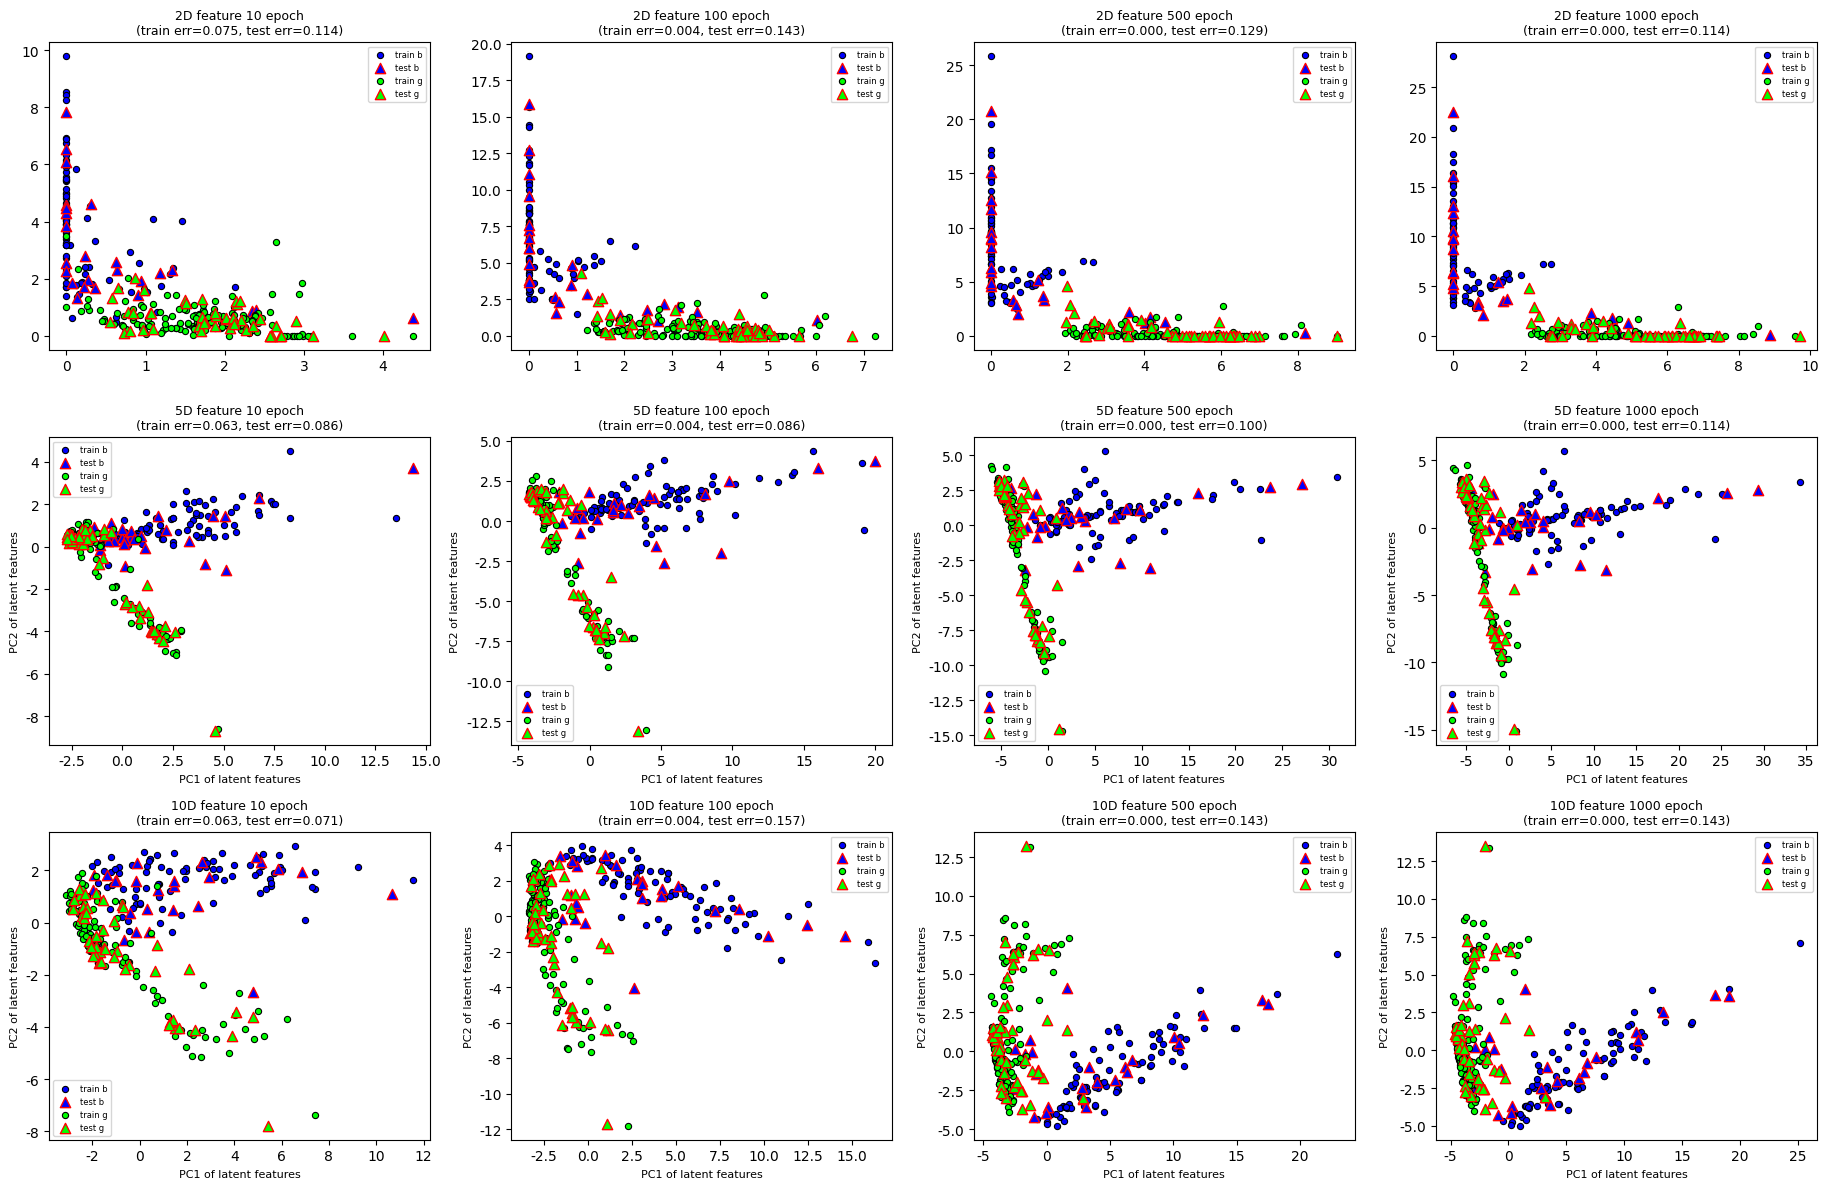

In [44]:
fig, axes = plt.subplots(len(LATENT_DIMS), len(SNAPSHOTS_AT),
                         figsize=(4.6 * len(SNAPSHOTS_AT), 4.0 * len(LATENT_DIMS)))
for r, dim in enumerate(LATENT_DIMS):
    _, _, snaps, rs = train_vis(d, dim, MAIN_SEED, VIS_CFG, SNAPSHOTS_AT)
    print(f"latent_dim={dim}: final train_err={rs['train_err']:.4f}, test_err={rs['test_err']:.4f}")
    for c_, ep in enumerate(SNAPSHOTS_AT):
        plot_latent_simple(axes[r, c_], snaps[ep][0], d["ytr"],
                           f"{dim}D feature {ep} epoch\n(train err={snaps[ep][4]:.3f}, test err={snaps[ep][5]:.3f})",
                           snaps[ep][1], d["yte"])
plt.tight_layout()
plt.savefig("compare_latent_dims.png", dpi=150)
plt.show()

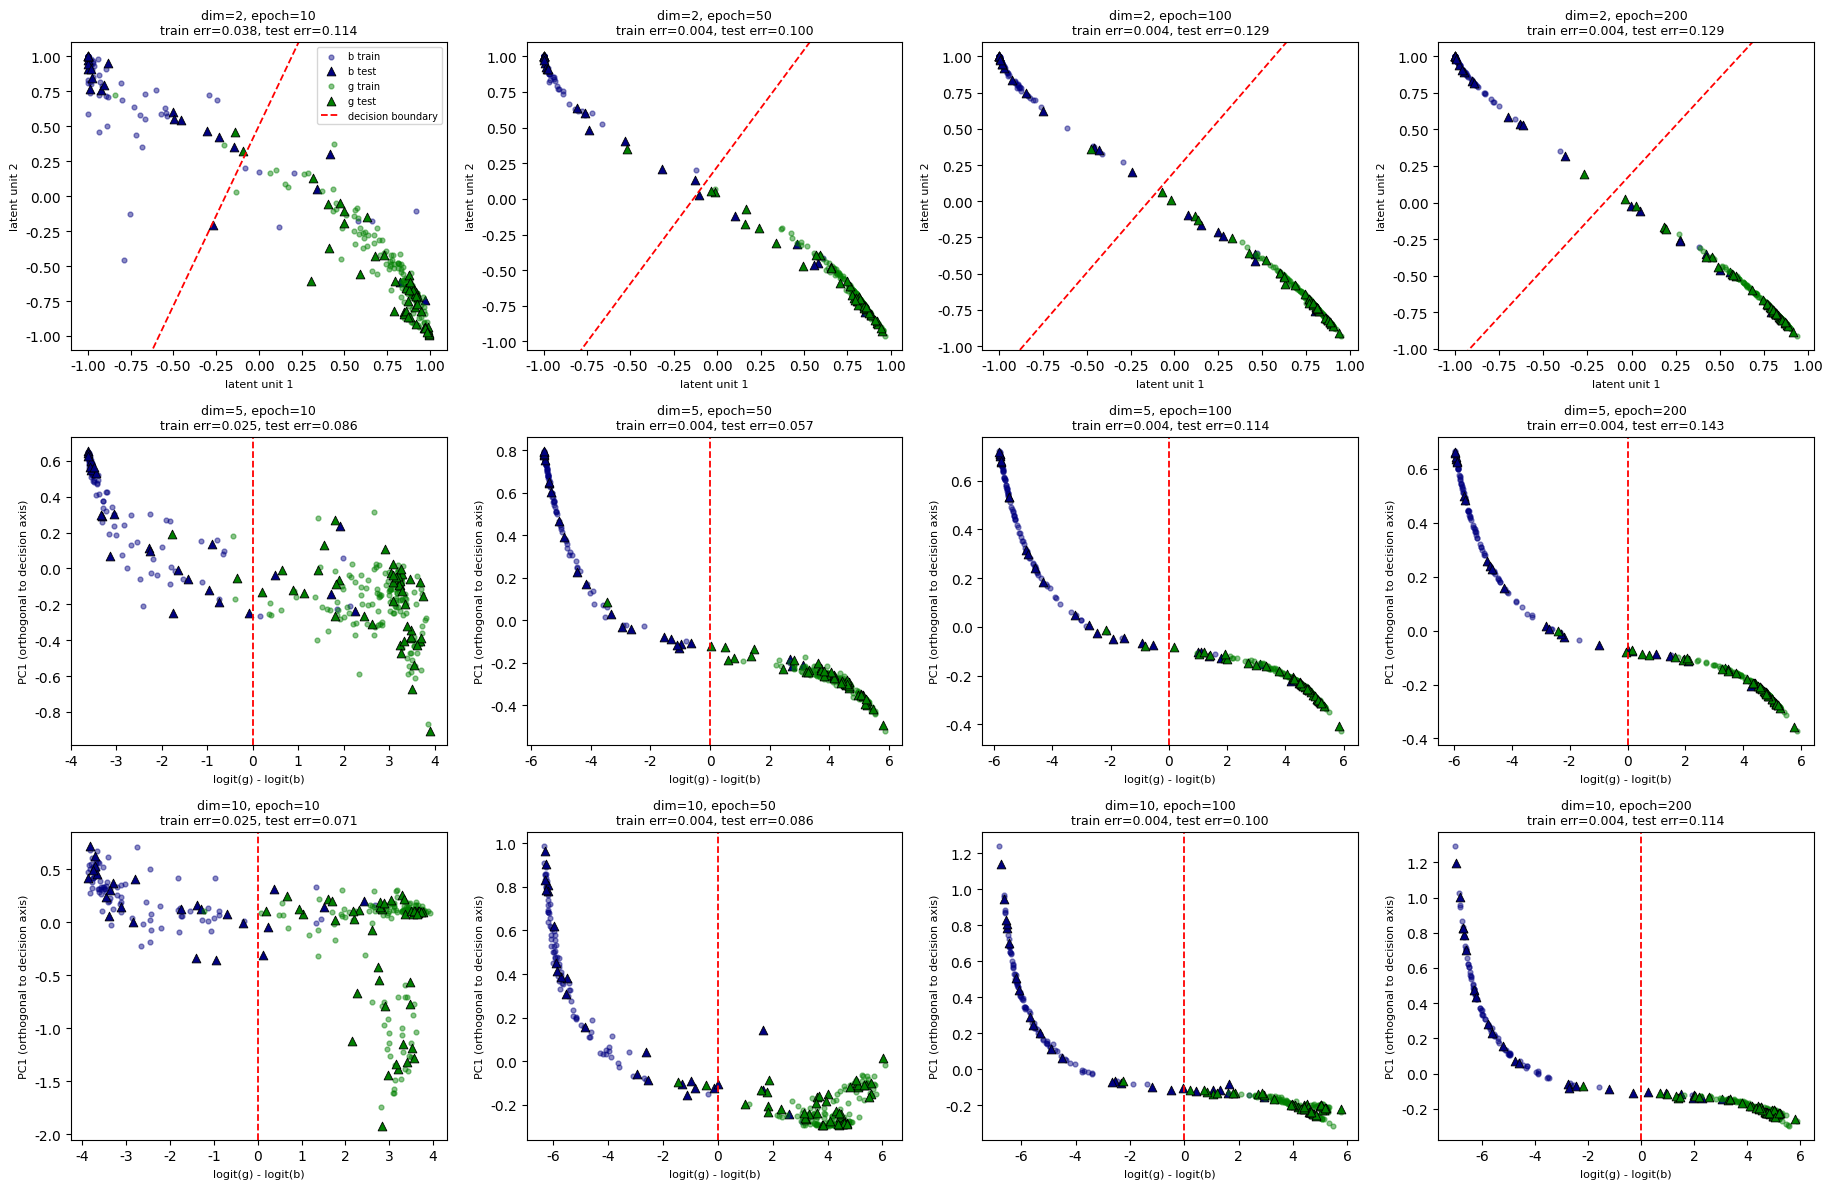

In [45]:
cfg_nostop = {**cfg, "patience": 0}
fig, axes = plt.subplots(len(LATENT_DIMS), len(SNAPSHOTS_SUP),
                         figsize=(4.6 * len(SNAPSHOTS_SUP), 4.0 * len(LATENT_DIMS)))
for r, dim in enumerate(LATENT_DIMS):
    _, _, snaps, _ = train(d, dim, MAIN_SEED, cfg_nostop, snapshots=SNAPSHOTS_SUP, track=False)
    for c_, ep in enumerate(SNAPSHOTS_SUP):
        s = snaps[ep]
        plot_latent(axes[r, c_], s, d["ytr"], d["yte"], dim,
                    f"dim={dim}, epoch={ep}\ntrain err={s[4]:.3f}, test err={s[5]:.3f}",
                    legend=(r == 0 and c_ == 0))
plt.tight_layout()
plt.savefig("compare_latent_dims_boundary.png", dpi=150)
plt.show()